# Preprocessing: Urban Street Tree Classification


**Dataset:** https://www.kaggle.com/datasets/erickendric/tree-dataset-of-urban-street-classification-tree
- 4804 images, 23 tree species classes
- Pre-split into train / val / test folders

In [20]:
import os

print("=== /kaggle/input ===")

if os.path.exists("/kaggle/input"):
    for item in os.listdir("/kaggle/input"):
        print(repr(item))
else:
    print("/kaggle/input does NOT exist")

=== /kaggle/input ===
'datasets'


In [21]:
import os

print("\n=== Recursive dataset search ===")

for root, dirs, files in os.walk("/kaggle/input"):
    print("ROOT:", root)
    print("DIRS:", dirs[:10])
    print("FILES:", files[:10])
    print("-" * 60)


=== Recursive dataset search ===
ROOT: /kaggle/input
DIRS: ['datasets']
FILES: []
------------------------------------------------------------
ROOT: /kaggle/input/datasets
DIRS: ['erickendric']
FILES: []
------------------------------------------------------------
ROOT: /kaggle/input/datasets/erickendric
DIRS: ['tree-dataset-of-urban-street-classification-tree']
FILES: []
------------------------------------------------------------
ROOT: /kaggle/input/datasets/erickendric/tree-dataset-of-urban-street-classification-tree
DIRS: ['tree']
FILES: []
------------------------------------------------------------
ROOT: /kaggle/input/datasets/erickendric/tree-dataset-of-urban-street-classification-tree/tree
DIRS: ['val', 'test', 'train']
FILES: []
------------------------------------------------------------
ROOT: /kaggle/input/datasets/erickendric/tree-dataset-of-urban-street-classification-tree/tree/val
DIRS: ['Osmanthus fragrans', 'Koelreuteria paniculata', 'Platanus', 'Triadica sebifera', 'C

# Data Preprocessing

This section describes the preprocessing pipeline used before training the image classification models. The objective is to prepare the tree image dataset consistently for ResNet-18, ResNet-50, and EfficientNet-B0 while preserving the original dataset structure and avoiding information leakage.

The preprocessing procedure consists of the following stages:

1. Dataset structure verification
2. Image integrity checking
3. Image format, dimensions, and aspect-ratio analysis
4. Exact duplicate detection
5. Near-duplicate and potential data-leakage analysis
6. Class distribution analysis
7. Image format standardization
8. Image resizing and cropping
9. Training data augmentation
10. Validation and test preprocessing
11. Pixel normalization
12. PyTorch dataset and DataLoader creation
13. Visual verification of the preprocessing pipeline

The dataset already provides separate training, validation, and test sets. These predefined splits are retained rather than creating a new random split. This prevents unnecessary changes to the experimental dataset and allows the models to be evaluated on the supplied test set.

All preprocessing operations are applied consistently across the experiments. Data augmentation is applied only to the training set, while validation and test images use deterministic preprocessing.


## Dataset Paths and Libraries

The dataset is stored in the Kaggle input directory. The dataset contains three predefined subsets: training, validation, and testing.

The preprocessing code uses Python, PIL for image inspection, pandas for tabular analysis, NumPy for numerical operations, and PyTorch/torchvision for the final model input pipeline.


In [25]:
from pathlib import Path
from collections import Counter
import hashlib
import random
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.datasets import ImageFolder

# Optional: perceptual hashing
try:
    import imagehash
except ImportError:
    !pip install -q ImageHash
    import imagehash


# ============================================================
# Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# Dataset paths
# ============================================================

DATASET_ROOT = Path(
    "/kaggle/input/datasets/erickendric/"
    "tree-dataset-of-urban-street-classification-tree/tree"
)

TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR   = DATASET_ROOT / "val"
TEST_DIR  = DATASET_ROOT / "test"


print("Dataset root:", DATASET_ROOT)
print("Train exists:", TRAIN_DIR.exists())
print("Validation exists:", VAL_DIR.exists())
print("Test exists:", TEST_DIR.exists())

Dataset root: /kaggle/input/datasets/erickendric/tree-dataset-of-urban-street-classification-tree/tree
Train exists: True
Validation exists: True
Test exists: True


## Dataset Structure Verification

The first step is to verify that the expected directory structure exists and that all three dataset splits are available.

The dataset is expected to follow the `ImageFolder` structure:

```text
tree/
├── train/
│   ├── class_1/
│   ├── class_2/
│   └── ...
├── val/
│   ├── class_1/
│   ├── class_2/
│   └── ...
└── test/
    ├── class_1/
    ├── class_2/
    └── ...
```

Each class directory represents one tree species. The class names are retained as the target labels.


In [26]:
SPLIT_DIRS = {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR
}

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
    ".tif",
    ".tiff"
}


def collect_images(split_dir):
    records = []

    for class_dir in sorted(split_dir.iterdir()):

        if not class_dir.is_dir():
            continue

        class_name = class_dir.name

        for path in sorted(class_dir.rglob("*")):

            if (
                path.is_file()
                and path.suffix.lower() in IMAGE_EXTENSIONS
            ):
                records.append({
                    "path": path,
                    "split": split_dir.name,
                    "class": class_name,
                    "filename": path.name
                })

    return records


all_records = []

for split_name, split_dir in SPLIT_DIRS.items():

    records = collect_images(split_dir)
    all_records.extend(records)

    print(
        f"{split_name.capitalize():5s}: "
        f"{len(records):,} images"
    )

print()
print(f"Total images: {len(all_records):,}")

Train: 3,850 images
Val  : 482 images
Test : 472 images

Total images: 4,804


## Class Verification

The classification task contains 23 tree species. The class directories in the training, validation, and test sets are compared to ensure that the same set of classes is available in every split.

Identical class sets are required because the classification problem must use the same target categories during training and evaluation.


In [27]:
def get_classes(split_dir):
    return sorted([
        directory.name
        for directory in split_dir.iterdir()
        if directory.is_dir()
    ])


train_classes = get_classes(TRAIN_DIR)
val_classes = get_classes(VAL_DIR)
test_classes = get_classes(TEST_DIR)

print("Number of classes:")
print("Train:", len(train_classes))
print("Val  :", len(val_classes))
print("Test :", len(test_classes))

print()
print("Class sets identical:")
print("Train == Val :", train_classes == val_classes)
print("Train == Test:", train_classes == test_classes)

assert train_classes == val_classes
assert train_classes == test_classes

print()
print("Classes:")

for index, class_name in enumerate(train_classes):
    print(f"{index:2d}: {class_name}")

Number of classes:
Train: 23
Val  : 23
Test : 23

Class sets identical:
Train == Val : True
Train == Test: True

Classes:
 0: Acer palmatum
 1: Cedrus deodara
 2: Celtis sinensis
 3: Cinnamomum camphora (Linn) Presl
 4: Elaeocarpus decipiens
 5: Flowering cherry
 6: Ginkgo biloba
 7: Koelreuteria paniculata
 8: Lagerstroemia indica
 9: Liquidambar formosana
10: Liriodendron chinense
11: Magnolia grandiflora L
12: Magnolia liliflora Desr
13: Michelia chapensis
14: Osmanthus fragrans
15: Photinia serratifolia
16: Platanus
17: Prunus cerasifera f. atropurpurea
18: Salix babylonica
19: Sapindus saponaria
20: Styphnolobium japonicum
21: Triadica sebifera
22: Zelkova serrata


## Image Integrity

Each image is checked to determine whether it can be successfully decoded. Corrupted, incomplete, or unsupported files can cause failures during model training, so they are identified before constructing the PyTorch datasets.

The `verify()` operation checks the integrity of the image file. Valid images are then reopened to obtain their dimensions and metadata.

No files are automatically deleted from the original dataset. Any invalid files are reported for inspection.


In [28]:
integrity_results = []

for record in all_records:

    path = record["path"]

    result = {
        "split": record["split"],
        "class": record["class"],
        "filename": record["filename"],
        "path": str(path),
        "valid": False,
        "format": None,
        "mode": None,
        "width": None,
        "height": None,
        "aspect_ratio": None,
        "error": None
    }

    try:

        # Verify file integrity
        with Image.open(path) as img:
            img.verify()

        # Reopen after verify()
        with Image.open(path) as img:

            width, height = img.size

            result["valid"] = True
            result["format"] = img.format
            result["mode"] = img.mode
            result["width"] = width
            result["height"] = height
            result["aspect_ratio"] = (
                width / height
                if height > 0
                else None
            )

    except Exception as e:

        result["error"] = (
            f"{type(e).__name__}: {e}"
        )

    integrity_results.append(result)


integrity_df = pd.DataFrame(
    integrity_results
)

print("Total images:", len(integrity_df))
print(
    "Valid images:",
    integrity_df["valid"].sum()
)
print(
    "Invalid images:",
    (~integrity_df["valid"]).sum()
)

Total images: 4804
Valid images: 4804
Invalid images: 0


In [29]:
corrupted_df = integrity_df[
    ~integrity_df["valid"]
].copy()

if corrupted_df.empty:

    print(
        "✓ No corrupted or unreadable images detected."
    )

else:

    print(
        f"⚠ {len(corrupted_df)} "
        "corrupted/unreadable images detected."
    )

    display(
        corrupted_df[
            [
                "split",
                "class",
                "filename",
                "path",
                "error"
            ]
        ]
    )

✓ No corrupted or unreadable images detected.


## Image Properties

The dataset may contain images stored using different file formats, color modes, resolutions, and aspect ratios. These properties are inspected before preprocessing.

The CNN models require a consistent three-channel RGB input. Images are therefore converted to RGB during preprocessing rather than modifying the original files.

The original aspect ratios are not forcibly distorted. For evaluation, images are resized while preserving their aspect ratio before a center crop is applied. Training images use random resized cropping with controlled crop ratios.


In [30]:
valid_df = integrity_df[
    integrity_df["valid"]
].copy()

print("Color modes:")
display(
    valid_df["mode"]
    .value_counts()
    .rename_axis("mode")
    .reset_index(name="count")
)

print("Image formats:")
display(
    valid_df["format"]
    .value_counts()
    .rename_axis("format")
    .reset_index(name="count")
)

print("Image dimensions:")
display(
    valid_df[
        ["width", "height"]
    ].describe()
)

print("Aspect ratio:")
display(
    valid_df["aspect_ratio"].describe()
)

Color modes:


,mode,count
0,RGB,4804


Image formats:


,format,count
0,JPEG,4804


Image dimensions:


,width,height
count,4804.000000,4804.000000
mean,1576.408826,1223.844921
std,94.996123,96.007766
min,837.000000,798.000000
25%,1600.000000,1200.000000
50%,1600.000000,1200.000000
75%,1600.000000,1200.000000
max,1600.000000,1600.000000


Aspect ratio:


count    4804.000000
mean        1.298969
std         0.139363
min         0.523125
25%         1.333333
50%         1.333333
75%         1.333333
max         2.005013
Name: aspect_ratio, dtype: float64

## Exact Duplicate Detection

Exact duplicate images are identified using SHA-256 file hashes. Two files with the same SHA-256 hash have identical file contents.

Duplicate detection is performed both within individual dataset splits and across splits. Cross-split duplicates are particularly important because an identical image appearing in both training and testing would introduce direct data leakage.

The original dataset is not modified automatically. Detected duplicates are reported for inspection.


In [31]:
def sha256_file(path, chunk_size=1024 * 1024):

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


print("Calculating SHA-256 hashes...")

integrity_df["sha256"] = [
    sha256_file(path)
    for path in integrity_df["path"]
]

print("Hashing completed.")

Calculating SHA-256 hashes...
Hashing completed.


In [32]:
hash_counts = (
    integrity_df
    .groupby("sha256")
    .size()
    .sort_values(ascending=False)
)

duplicate_hashes = hash_counts[
    hash_counts > 1
]

print(
    "Exact duplicate groups:",
    len(duplicate_hashes)
)

print(
    "Files in duplicate groups:",
    duplicate_hashes.sum()
)

Exact duplicate groups: 45
Files in duplicate groups: 94


In [33]:
if duplicate_hashes.empty:

    print(
        "✓ No exact duplicate files detected."
    )

else:

    exact_duplicates_df = (
        integrity_df[
            integrity_df["sha256"].isin(
                duplicate_hashes.index
            )
        ]
        .sort_values(
            ["sha256", "split", "class"]
        )
    )

    display(
        exact_duplicates_df[
            [
                "sha256",
                "split",
                "class",
                "filename",
                "path"
            ]
        ]
    )

,sha256,split,class,filename,path
2612,08d41721f19dbf5042da9344fd5bdd595d8194114e43fd...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (136).JPG,/kaggle/input/datasets/erickendric/tree-datase...
2674,08d41721f19dbf5042da9344fd5bdd595d8194114e43fd...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (64).JPG,/kaggle/input/datasets/erickendric/tree-datase...
3814,0ba9c200e4522d377576ac23ffce52b8a0d70c5b44abbd...,train,Zelkova serrata,Zelkova serrata_tree_1 (61).jpg,/kaggle/input/datasets/erickendric/tree-datase...
4315,0ba9c200e4522d377576ac23ffce52b8a0d70c5b44abbd...,val,Zelkova serrata,Zelkova serrata_tree_1 (146).jpg,/kaggle/input/datasets/erickendric/tree-datase...
908,17edc09897f71ff526e1623592d21b287b05cf1c20abee...,train,Flowering cherry,Flowering cherry_tree_1 (132).jpg,/kaggle/input/datasets/erickendric/tree-datase...
...,...,...,...,...,...
4184,f94f3b418124f1d48f113eb8fee79ced838296c5915a57...,val,Photinia serratifolia,Photinia serratifolia_tree_1 (69).JPG,/kaggle/input/datasets/erickendric/tree-datase...
2600,f9c17577f200fb750178c2f3f0d770e6a0678288c4b365...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (120).JPG,/kaggle/input/datasets/erickendric/tree-datase...
2680,f9c17577f200fb750178c2f3f0d770e6a0678288c4b365...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (71).JPG,/kaggle/input/datasets/erickendric/tree-datase...
2608,fd010a2510104682f0d66ffc3cab4a8a18a90f723ae0f8...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (131).JPG,/kaggle/input/datasets/erickendric/tree-datase...


## Cross-Split Exact Duplicate Check

The most important duplicate check is whether identical files occur in different dataset splits.

A duplicate within the training set does not directly cause train-test leakage. However, an identical image occurring across training, validation, or test sets can compromise the independence of the evaluation data.

Therefore, cross-split exact duplicates are reported separately.


In [34]:
cross_split_exact_groups = []

for hash_value, group in integrity_df.groupby("sha256"):

    if group["split"].nunique() > 1:

        cross_split_exact_groups.append(group)


if cross_split_exact_groups:

    cross_split_exact_df = pd.concat(
        cross_split_exact_groups
    ).sort_values(
        ["sha256", "split"]
    )

    print(
        "⚠ Cross-split exact duplicates detected:"
    )

    display(
        cross_split_exact_df[
            [
                "sha256",
                "split",
                "class",
                "filename",
                "path"
            ]
        ]
    )

else:

    cross_split_exact_df = pd.DataFrame()

    print(
        "✓ No exact duplicates were found "
        "across train, validation, and test."
    )

⚠ Cross-split exact duplicates detected:


,sha256,split,class,filename,path
3814,0ba9c200e4522d377576ac23ffce52b8a0d70c5b44abbd...,train,Zelkova serrata,Zelkova serrata_tree_1 (61).jpg,/kaggle/input/datasets/erickendric/tree-datase...
4315,0ba9c200e4522d377576ac23ffce52b8a0d70c5b44abbd...,val,Zelkova serrata,Zelkova serrata_tree_1 (146).jpg,/kaggle/input/datasets/erickendric/tree-datase...
905,2479d80949ca5d28037302670b9234415c87d3fc985543...,train,Flowering cherry,Flowering cherry_tree_1 (129).jpg,/kaggle/input/datasets/erickendric/tree-datase...
3969,2479d80949ca5d28037302670b9234415c87d3fc985543...,val,Flowering cherry,Flowering cherry_tree_1 (58).jpg,/kaggle/input/datasets/erickendric/tree-datase...
2653,3399e14f23900f317971241c304362af0a06023feb8889...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (41).JPG,/kaggle/input/datasets/erickendric/tree-datase...
4179,3399e14f23900f317971241c304362af0a06023feb8889...,val,Photinia serratifolia,Photinia serratifolia_tree_1 (129).JPG,/kaggle/input/datasets/erickendric/tree-datase...
2614,4631844466fcdd04a7bf2bbf01f6d04d68ce907320fdd1...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (139).JPG,/kaggle/input/datasets/erickendric/tree-datase...
2677,4631844466fcdd04a7bf2bbf01f6d04d68ce907320fdd1...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (68).JPG,/kaggle/input/datasets/erickendric/tree-datase...
4177,4631844466fcdd04a7bf2bbf01f6d04d68ce907320fdd1...,val,Photinia serratifolia,Photinia serratifolia_tree_1 (117).JPG,/kaggle/input/datasets/erickendric/tree-datase...
3140,691f445bcb28640aae93e41f7373260426a730f662c7b6...,train,Sapindus saponaria,Sapindus saponaria_tree_1 (11).jpg,/kaggle/input/datasets/erickendric/tree-datase...


## Near-Duplicate Detection

Exact file hashing cannot detect images that contain the same or highly similar visual content but have been resized, recompressed, or saved using different file formats.

Perceptual hashing is therefore used to identify potential near-duplicate images. A perceptual hash represents the visual structure of an image, and visually similar images tend to have a small Hamming distance between their hashes.

Near-duplicate detection is used as a screening method rather than an automatic deletion rule. A small perceptual distance indicates that images should be inspected, but does not by itself prove that data leakage exists.

A pHash Hamming distance threshold of 6 is used as an initial conservative screening threshold.


In [35]:
def calculate_phash(path):

    with Image.open(path) as img:

        img = img.convert("RGB")

        return imagehash.phash(img)


valid_paths = integrity_df[
    integrity_df["valid"]
]["path"].tolist()

print(
    f"Calculating perceptual hashes "
    f"for {len(valid_paths):,} images..."
)

phash_values = []

for path in valid_paths:

    try:
        phash_values.append(
            str(calculate_phash(path))
        )

    except Exception:
        phash_values.append(None)


phash_df = pd.DataFrame({
    "path": valid_paths,
    "phash": phash_values
})

integrity_df = integrity_df.merge(
    phash_df,
    on="path",
    how="left"
)

print("Perceptual hashing completed.")

Calculating perceptual hashes for 4,804 images...
Perceptual hashing completed.


In [36]:
from itertools import combinations

NEAR_DUPLICATE_THRESHOLD = 6

near_df = integrity_df[
    integrity_df["valid"] &
    integrity_df["phash"].notna()
].reset_index(drop=True)

near_df["phash_obj"] = near_df[
    "phash"
].apply(imagehash.hex_to_hash)


near_duplicate_pairs = []

n = len(near_df)

print(
    f"Comparing {n:,} valid images..."
)

for i, j in combinations(range(n), 2):

    distance = (
        near_df.loc[i, "phash_obj"]
        -
        near_df.loc[j, "phash_obj"]
    )

    if distance <= NEAR_DUPLICATE_THRESHOLD:

        image_1 = near_df.loc[i]
        image_2 = near_df.loc[j]

        near_duplicate_pairs.append({

            "distance": distance,

            "split_1": image_1["split"],
            "class_1": image_1["class"],
            "filename_1": image_1["filename"],
            "path_1": image_1["path"],

            "split_2": image_2["split"],
            "class_2": image_2["class"],
            "filename_2": image_2["filename"],
            "path_2": image_2["path"],
        })


near_duplicates_df = pd.DataFrame(
    near_duplicate_pairs
)

print(
    "Potential near-duplicate pairs:",
    len(near_duplicates_df)
)

Comparing 4,804 valid images...
Potential near-duplicate pairs: 101


In [37]:
if near_duplicates_df.empty:

    print(
        "✓ No near-duplicate candidates detected."
    )

else:

    display(
        near_duplicates_df
        .sort_values("distance")
        .head(100)
    )

,distance,split_1,class_1,filename_1,path_1,split_2,class_2,filename_2,path_2
1,0,train,Acer palmatum,Acer palmatum_tree_1 (15).jpg,/kaggle/input/datasets/erickendric/tree-datase...,train,Acer palmatum,Acer palmatum_tree_1 (16).jpg,/kaggle/input/datasets/erickendric/tree-datase...
2,0,train,Cedrus deodara,Cedrus deodara_tree_1 (20).jpg,/kaggle/input/datasets/erickendric/tree-datase...,train,Cedrus deodara,Cedrus deodara_tree_1 (24).jpg,/kaggle/input/datasets/erickendric/tree-datase...
5,0,train,Flowering cherry,Flowering cherry_tree_1 (129).jpg,/kaggle/input/datasets/erickendric/tree-datase...,val,Flowering cherry,Flowering cherry_tree_1 (58).jpg,/kaggle/input/datasets/erickendric/tree-datase...
4,0,train,Flowering cherry,Flowering cherry_tree_1 (128).jpg,/kaggle/input/datasets/erickendric/tree-datase...,train,Flowering cherry,Flowering cherry_tree_1 (47).jpg,/kaggle/input/datasets/erickendric/tree-datase...
6,0,train,Flowering cherry,Flowering cherry_tree_1 (131).jpg,/kaggle/input/datasets/erickendric/tree-datase...,train,Flowering cherry,Flowering cherry_tree_1 (80).jpg,/kaggle/input/datasets/erickendric/tree-datase...
...,...,...,...,...,...,...,...,...,...
71,6,train,Salix babylonica,Salix babylonica_tree_1 (55).jpg,/kaggle/input/datasets/erickendric/tree-datase...,train,Salix babylonica,Salix babylonica_tree_1 (56).jpg,/kaggle/input/datasets/erickendric/tree-datase...
88,6,train,Triadica sebifera,Triadica sebifera_tree_1 (30).jpg,/kaggle/input/datasets/erickendric/tree-datase...,train,Triadica sebifera,Triadica sebifera_tree_1 (31).jpg,/kaggle/input/datasets/erickendric/tree-datase...
82,6,train,Sapindus saponaria,Sapindus saponaria_tree_1 (274).JPG,/kaggle/input/datasets/erickendric/tree-datase...,val,Sapindus saponaria,Sapindus saponaria_tree_1 (275).JPG,/kaggle/input/datasets/erickendric/tree-datase...
69,6,train,Platanus,Platanus_tree_1 (1).jpg,/kaggle/input/datasets/erickendric/tree-datase...,train,Platanus,Platanus_tree_1 (2).jpg,/kaggle/input/datasets/erickendric/tree-datase...


## Cross-Split Near-Duplicate Analysis

Near-duplicate candidates are filtered to identify pairs occurring in different dataset splits.

Particular attention is given to train-test and train-validation pairs because visually similar images originating from the same source can make evaluation less independent.

These results are treated as candidates for manual inspection rather than automatic evidence of leakage.


In [38]:
if near_duplicates_df.empty:

    cross_split_near_df = pd.DataFrame()

else:

    cross_split_near_df = (
        near_duplicates_df[
            near_duplicates_df["split_1"]
            !=
            near_duplicates_df["split_2"]
        ]
        .sort_values("distance")
        .copy()
    )


print(
    "Cross-split near-duplicate pairs:",
    len(cross_split_near_df)
)

if not cross_split_near_df.empty:

    display(
        cross_split_near_df.head(100)
    )

Cross-split near-duplicate pairs: 25


,distance,split_1,class_1,filename_1,path_1,split_2,class_2,filename_2,path_2
5,0,train,Flowering cherry,Flowering cherry_tree_1 (129).jpg,/kaggle/input/datasets/erickendric/tree-datase...,val,Flowering cherry,Flowering cherry_tree_1 (58).jpg,/kaggle/input/datasets/erickendric/tree-datase...
13,0,train,Flowering cherry,Flowering cherry_tree_1 (69).jpg,/kaggle/input/datasets/erickendric/tree-datase...,val,Flowering cherry,Flowering cherry_tree_1 (130).jpg,/kaggle/input/datasets/erickendric/tree-datase...
30,0,train,Magnolia grandiflora L,Magnolia grandiflora L_tree_1 (239).JPG,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,Magnolia grandiflora L_tree_1 (251).JPG,/kaggle/input/datasets/erickendric/tree-datase...
25,0,train,Liquidambar formosana,Liquidambar formosana_tree_1 (154).jpg,/kaggle/input/datasets/erickendric/tree-datase...,val,Liquidambar formosana,Liquidambar formosana_tree_1 (90).jpg,/kaggle/input/datasets/erickendric/tree-datase...
35,0,train,Magnolia grandiflora L,Magnolia grandiflora L_tree_1 (246).JPG,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,Magnolia grandiflora L_tree_1 (258).JPG,/kaggle/input/datasets/erickendric/tree-datase...
36,0,train,Magnolia grandiflora L,Magnolia grandiflora L_tree_1 (248).JPG,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,Magnolia grandiflora L_tree_1 (236).JPG,/kaggle/input/datasets/erickendric/tree-datase...
46,0,train,Photinia serratifolia,Photinia serratifolia_tree_1 (118).JPG,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,Photinia serratifolia_tree_1 (69).JPG,/kaggle/input/datasets/erickendric/tree-datase...
37,0,train,Magnolia grandiflora L,Magnolia grandiflora L_tree_1 (255).JPG,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,Magnolia grandiflora L_tree_1 (243).JPG,/kaggle/input/datasets/erickendric/tree-datase...
63,0,train,Photinia serratifolia,Photinia serratifolia_tree_1 (140).JPG,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,Photinia serratifolia_tree_1 (69).JPG,/kaggle/input/datasets/erickendric/tree-datase...
64,0,train,Photinia serratifolia,Photinia serratifolia_tree_1 (26).JPG,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,Photinia serratifolia_tree_1 (123).JPG,/kaggle/input/datasets/erickendric/tree-datase...


## Class Distribution Analysis

The number of images in each class is calculated separately for the training, validation, and test sets.

The dataset contains 23 tree species. The distribution is not perfectly balanced, with different numbers of images available for each species. The class distribution is therefore reported rather than assuming that all classes contain the same number of samples.

The baseline experiment retains the original training distribution. No oversampling or synthetic image generation is introduced at this stage. Class weighting or sampling strategies can be evaluated later as separate experiments if class imbalance is shown to affect model performance.


In [39]:
distribution = (
    integrity_df
    .groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
)

distribution["total"] = distribution.sum(axis=1)

distribution = distribution[
    ["train", "val", "test", "total"]
]

display(distribution)

split,train,val,test,total
class,,,,
Acer palmatum,162,21,20,203
Cedrus deodara,125,16,15,156
Celtis sinensis,188,24,23,235
Cinnamomum camphora (Linn) Presl,234,29,29,292
Elaeocarpus decipiens,172,23,21,216
Flowering cherry,106,13,13,132
Ginkgo biloba,228,28,28,284
Koelreuteria paniculata,223,28,28,279
Lagerstroemia indica,65,8,8,81


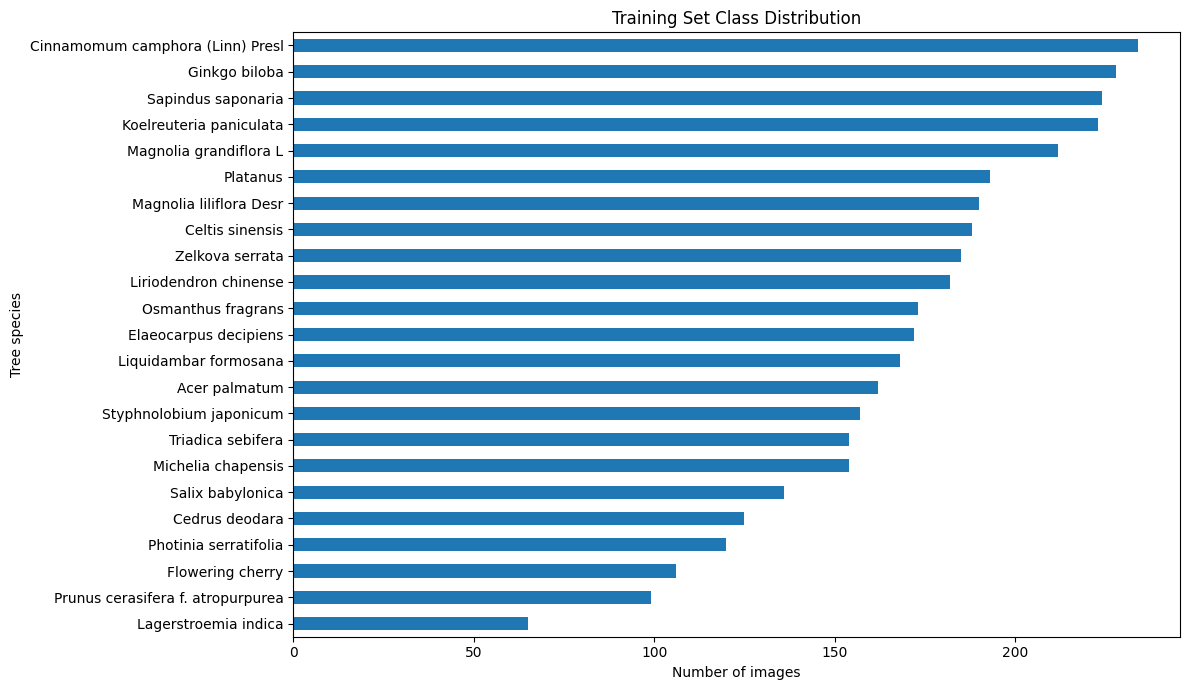

In [40]:
plt.figure(figsize=(12, 7))

distribution["train"].sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of images")
plt.ylabel("Tree species")
plt.title("Training Set Class Distribution")
plt.tight_layout()
plt.show()

In [41]:
train_counts = distribution["train"]

largest_class = train_counts.max()
smallest_class = train_counts.min()

largest_class_name = train_counts.idxmax()
smallest_class_name = train_counts.idxmin()

imbalance_ratio = (
    largest_class / smallest_class
)

print(
    f"Largest training class: "
    f"{largest_class_name} ({largest_class})"
)

print(
    f"Smallest training class: "
    f"{smallest_class_name} ({smallest_class})"
)

print(
    f"Largest/smallest ratio: "
    f"{imbalance_ratio:.2f}x"
)

Largest training class: Cinnamomum camphora (Linn) Presl (234)
Smallest training class: Lagerstroemia indica (65)
Largest/smallest ratio: 3.60x


## Class Imbalance Strategy

The training data contains moderate class imbalance. The baseline preprocessing pipeline does not artificially equalize the class frequencies because changing the original distribution could introduce another experimental variable.

Instead, the original training distribution is retained for the baseline models.

If later experiments indicate that minority classes receive substantially poorer performance, class-weighted loss or a weighted sampling strategy can be evaluated as a separate experiment. Validation and test distributions are not artificially balanced because they should represent the original evaluation distribution.


## Image Size

A target resolution of **224 × 224 pixels** is used for all three CNN architectures.

This resolution is appropriate for ResNet-18, ResNet-50, and EfficientNet-B0 with ImageNet-pretrained weights and provides a practical balance between visual information and computational requirements.

Using the same target resolution also keeps the comparison between architectures consistent.


## RGB Conversion

All images are converted to three-channel RGB during preprocessing.

The original image files are not modified. RGB conversion is performed dynamically when an image is loaded.

This provides a consistent three-channel input representation regardless of whether the source image is grayscale, RGBA, or another supported image mode.


## Training Preprocessing and Data Augmentation

Training images are subjected to moderate data augmentation to improve model generalization and reduce overfitting.

The training pipeline uses random resized cropping, horizontal flipping, small rotations, and mild color variation.

The augmentations are intentionally limited because tree species can contain important visual characteristics in leaf shape, bark texture, flower color, and foliage color. Excessive augmentation could remove or alter these discriminative characteristics.

The training transformation is applied independently each time an image is loaded, meaning that the same original image can produce different augmented versions during different training epochs.


In [42]:
IMAGE_SIZE = 224
RESIZE_SIZE = 256

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


train_transform = transforms.Compose([

    # Ensure three-channel input
    transforms.Lambda(
        lambda img: img.convert("RGB")
    ),

    # Controlled spatial augmentation
    transforms.RandomResizedCrop(
        size=IMAGE_SIZE,
        scale=(0.80, 1.00),
        ratio=(0.90, 1.10)
    ),

    # Horizontal orientation variation
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    # Small geometric variation
    transforms.RandomRotation(
        degrees=10
    ),

    # Mild lighting/color variation
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    # Convert to tensor
    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

## Validation and Test Preprocessing

Validation and test images are not augmented because evaluation should measure model performance under a deterministic and consistent preprocessing procedure.

The shorter image dimension is first resized to 256 pixels while preserving the original aspect ratio. A 224 × 224 center crop is then extracted.

No random crop, rotation, flipping, or color modification is applied during validation or testing.

This ensures that changes in validation and test predictions are caused by the model rather than random preprocessing.


In [43]:
eval_transform = transforms.Compose([

    # Ensure RGB
    transforms.Lambda(
        lambda img: img.convert("RGB")
    ),

    # Preserve aspect ratio
    transforms.Resize(
        RESIZE_SIZE
    ),

    # Deterministic crop
    transforms.CenterCrop(
        IMAGE_SIZE
    ),

    # Tensor conversion
    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

## Padding Decision

Padding is not used in the baseline preprocessing pipeline.

Instead, images are cropped to the required 224 × 224 input size. Padding could introduce artificial borders or background regions that are not present in the original photographs.

Random resized cropping is used during training, while resize and center crop are used during validation and testing.


## PyTorch Dataset Construction

The `ImageFolder` dataset implementation is used because the dataset follows a class-directory structure.

The training dataset receives the stochastic augmentation pipeline, while validation and test datasets receive the deterministic evaluation pipeline.


In [44]:
train_dataset = ImageFolder(
    root=str(TRAIN_DIR),
    transform=train_transform
)

val_dataset = ImageFolder(
    root=str(VAL_DIR),
    transform=eval_transform
)

test_dataset = ImageFolder(
    root=str(TEST_DIR),
    transform=eval_transform
)


print("Dataset sizes:")
print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))

print()
print("Classes:")
print(train_dataset.classes)

Dataset sizes:
Train: 3850
Val  : 482
Test : 472

Classes:
['Acer palmatum', 'Cedrus deodara', 'Celtis sinensis', 'Cinnamomum camphora (Linn) Presl', 'Elaeocarpus decipiens', 'Flowering cherry', 'Ginkgo biloba', 'Koelreuteria paniculata', 'Lagerstroemia indica', 'Liquidambar formosana', 'Liriodendron chinense', 'Magnolia grandiflora L', 'Magnolia liliflora Desr', 'Michelia chapensis', 'Osmanthus fragrans', 'Photinia serratifolia', 'Platanus', 'Prunus cerasifera f. atropurpurea', 'Salix babylonica', 'Sapindus saponaria', 'Styphnolobium japonicum', 'Triadica sebifera', 'Zelkova serrata']


## Class Mapping Verification

The class-to-index mapping must be identical across the three datasets. This prevents a situation in which the same numerical target represents different tree species in different splits.


In [45]:
assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

print("✓ Class mappings are identical.")

for class_name, index in train_dataset.class_to_idx.items():
    print(f"{index:2d}: {class_name}")

✓ Class mappings are identical.
 0: Acer palmatum
 1: Cedrus deodara
 2: Celtis sinensis
 3: Cinnamomum camphora (Linn) Presl
 4: Elaeocarpus decipiens
 5: Flowering cherry
 6: Ginkgo biloba
 7: Koelreuteria paniculata
 8: Lagerstroemia indica
 9: Liquidambar formosana
10: Liriodendron chinense
11: Magnolia grandiflora L
12: Magnolia liliflora Desr
13: Michelia chapensis
14: Osmanthus fragrans
15: Photinia serratifolia
16: Platanus
17: Prunus cerasifera f. atropurpurea
18: Salix babylonica
19: Sapindus saponaria
20: Styphnolobium japonicum
21: Triadica sebifera
22: Zelkova serrata


## DataLoader Configuration

The datasets are converted into PyTorch DataLoaders.

A batch size of 32 is used as the baseline. Training data is shuffled to reduce ordering effects during optimization, while validation and test data are not shuffled because their ordering does not affect evaluation.

The DataLoaders use multiple workers where supported by the Kaggle environment.


In [47]:
BATCH_SIZE = 32

NUM_WORKERS = 2

PIN_MEMORY = torch.cuda.is_available()


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)


print("DataLoaders created.")

print(
    "Training batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

DataLoaders created.
Training batches: 121
Validation batches: 16
Test batches: 15


## Tensor Verification

A batch is extracted from the training DataLoader to verify that the preprocessing pipeline produces the expected tensor representation.

The expected format is:

```text
[batch_size, channels, height, width]
```

with three RGB channels and a spatial resolution of 224 × 224 pixels.

Because ImageNet normalization is applied, the tensor values are no longer restricted to the `[0, 1]` range.


In [48]:
images, labels = next(iter(train_loader))

print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)

print()
print("Expected:")
print(
    f"Images: [batch_size, 3, {IMAGE_SIZE}, {IMAGE_SIZE}]"
)

print()
print("Tensor minimum:", images.min().item())
print("Tensor maximum:", images.max().item())
print("Tensor mean:", images.mean().item())
print("Tensor std:", images.std().item())

Image tensor shape: torch.Size([32, 3, 224, 224])
Label tensor shape: torch.Size([32])

Expected:
Images: [batch_size, 3, 224, 224]

Tensor minimum: -2.1179039478302
Tensor maximum: 2.640000104904175
Tensor mean: -0.13932116329669952
Tensor std: 1.2105692625045776


In [49]:
assert images.ndim == 4
assert images.shape[1] == 3
assert images.shape[2] == IMAGE_SIZE
assert images.shape[3] == IMAGE_SIZE

print(
    "✓ Tensor shape verification passed."
)

✓ Tensor shape verification passed.


## Augmentation Verification

The training transformations are visually inspected to ensure that the augmentation pipeline produces realistic images.

The normalized tensors are temporarily converted back to the approximate RGB range for visualization. This visualization is only for quality control and does not alter the training data.


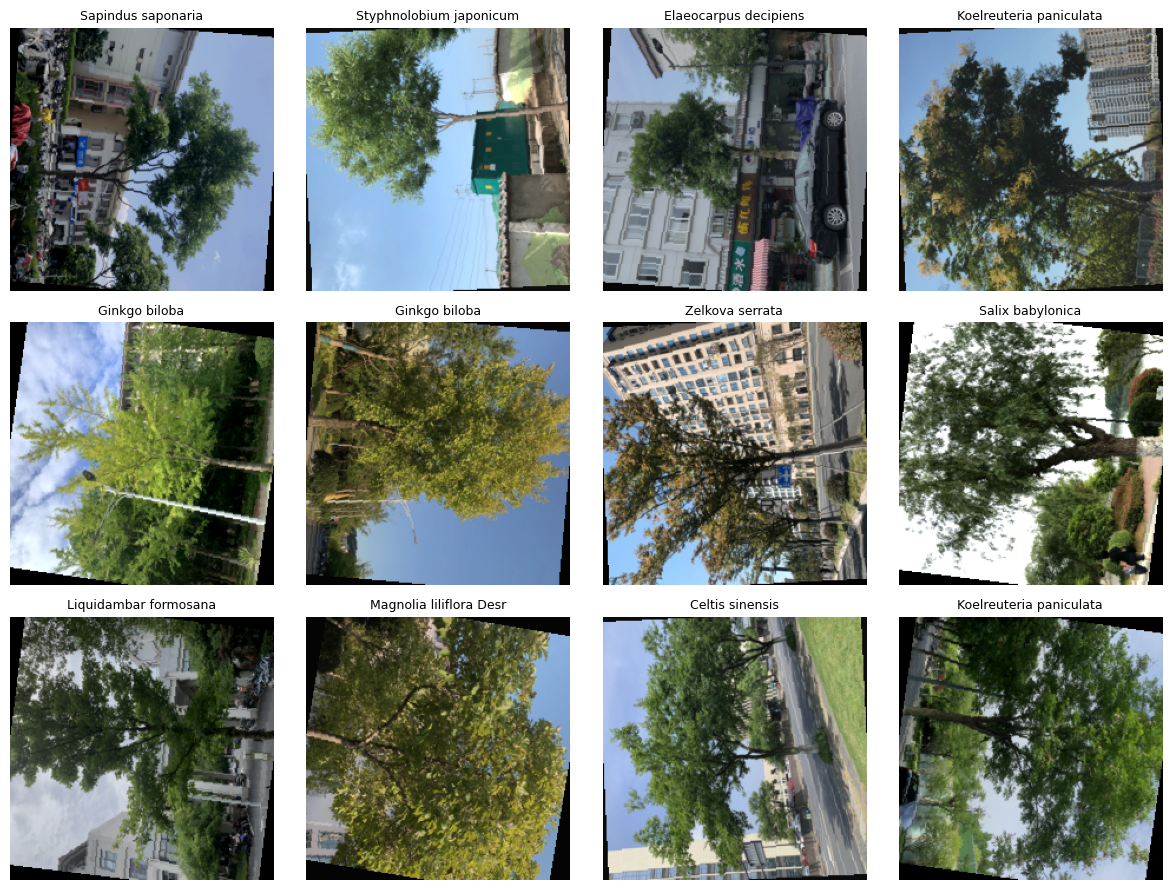

In [50]:
def denormalize(image_tensor):

    mean = torch.tensor(
        IMAGENET_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        IMAGENET_STD
    ).view(3, 1, 1)

    image = image_tensor.cpu() * std + mean

    return image.clamp(0, 1)


fig, axes = plt.subplots(
    3,
    4,
    figsize=(12, 9)
)

for ax in axes.flat:

    idx = np.random.randint(
        0,
        len(train_dataset)
    )

    image, label = train_dataset[idx]

    image = denormalize(image)

    ax.imshow(
        image.permute(1, 2, 0)
    )

    ax.set_title(
        train_dataset.classes[label],
        fontsize=9
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

## Validation and Test Preprocessing Verification

Validation and test preprocessing is deterministic. A small sample is visualized to verify that the resize-and-center-crop procedure retains the relevant visual content of the original tree images.


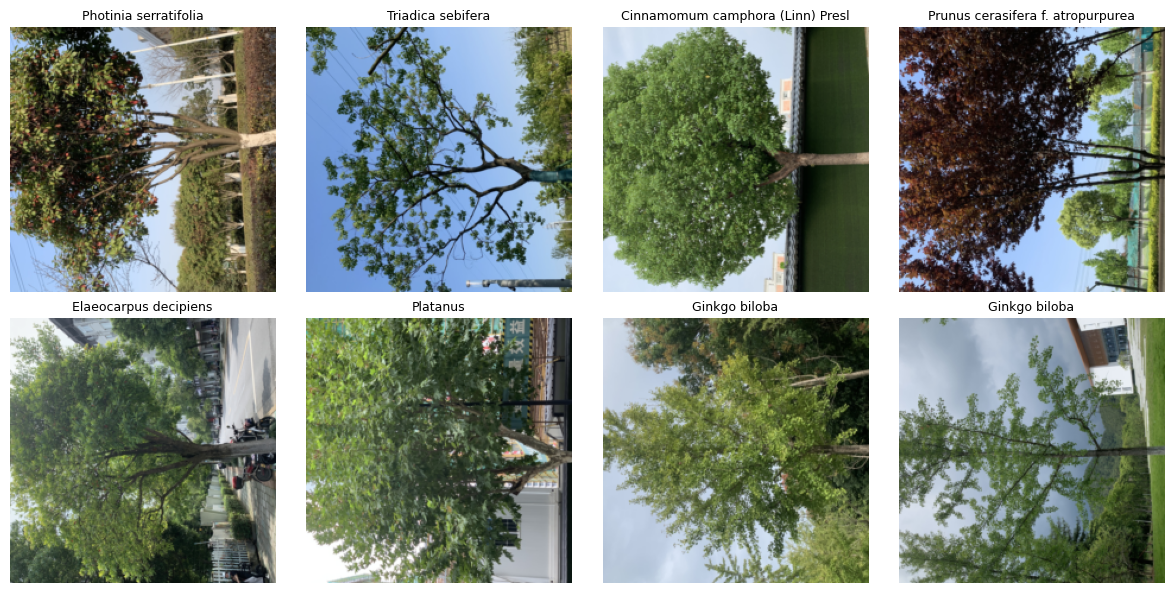

In [51]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(12, 6)
)

for ax in axes.flat:

    idx = np.random.randint(
        0,
        len(val_dataset)
    )

    image, label = val_dataset[idx]

    image = denormalize(image)

    ax.imshow(
        image.permute(1, 2, 0)
    )

    ax.set_title(
        val_dataset.classes[label],
        fontsize=9
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

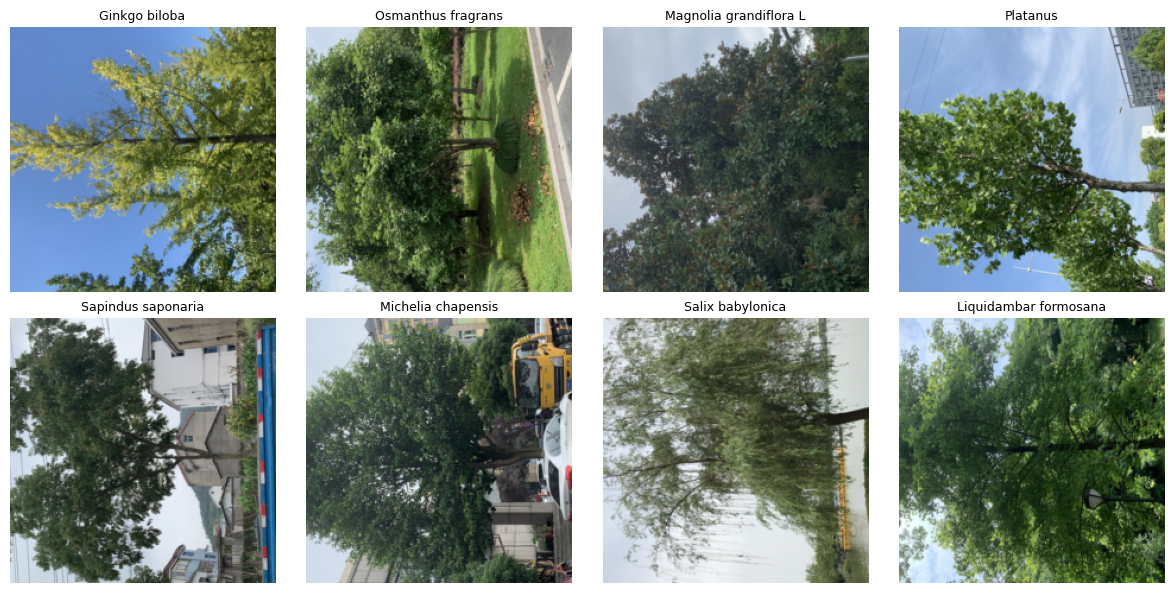

In [52]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(12, 6)
)

for ax in axes.flat:

    idx = np.random.randint(
        0,
        len(val_dataset)
    )

    image, label = val_dataset[idx]

    image = denormalize(image)

    ax.imshow(
        image.permute(1, 2, 0)
    )

    ax.set_title(
        val_dataset.classes[label],
        fontsize=9
    )

    ax.axis("off")


plt.tight_layout()
plt.show()